## Q1. Data Loading & Understanding

a) Load the dataset into Python.

In [17]:
import pandas as pd
import os

# Dynamically select the file if already uploaded
file_name = 'loan_approval (1).xlsx' if os.path.exists('loan_approval (1).xlsx') else ('loan_approval.xlsx' if os.path.exists('loan_approval.xlsx') else None)

if not file_name:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))

# Read the file using the correct Excel reader
df = pd.read_excel(file_name)

# Display first 5 rows
df.head()

,name,city,income,credit_score,loan_amount,years_employed,points,loan_approved
0,Allison Hill,East Jill,113810,389,39698,27,50,False
1,Brandon Hall,New Jamesside,44592,729,15446,28,55,False
2,Rhonda Smith,Lake Roberto,33278,584,11189,13,45,False
3,Gabrielle Davis,West Melanieview,127196,344,48823,29,50,False
4,Valerie Gray,Mariastad,66048,496,47174,4,25,False


**b) Display the first 5 rows.**

In [19]:
df.head()

,name,city,income,credit_score,loan_amount,years_employed,points,loan_approved
0,Allison Hill,East Jill,113810,389,39698,27,50,False
1,Brandon Hall,New Jamesside,44592,729,15446,28,55,False
2,Rhonda Smith,Lake Roberto,33278,584,11189,13,45,False
3,Gabrielle Davis,West Melanieview,127196,344,48823,29,50,False
4,Valerie Gray,Mariastad,66048,496,47174,4,25,False


**c) Check the shape of the dataset**

In [20]:
df.shape

(2000, 8)

**d) Display the data types of each column.**

In [21]:
df.dtypes

,0
name,object
city,object
income,int64
credit_score,int64
loan_amount,int64
years_employed,int64
points,int64
loan_approved,bool


###Q2. Data Cleaning

**a) Check for missing values in the dataset.**

In [22]:
df.isnull().sum()

,0
name,0
city,0
income,0
credit_score,0
loan_amount,0
years_employed,0
points,0
loan_approved,0


**b) Handle missing values appropriately.**

In [23]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_cols:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values handled")

Missing values handled


**c) Identify categorical columns present in the dataset.**

In [24]:
df.select_dtypes(
    include=["object", "category"]
).columns

Index(['name', 'city'], dtype='object')

##Q3. Exploratory Data Analysis (EDA)

**a) Plot the distribution of the target variable.**

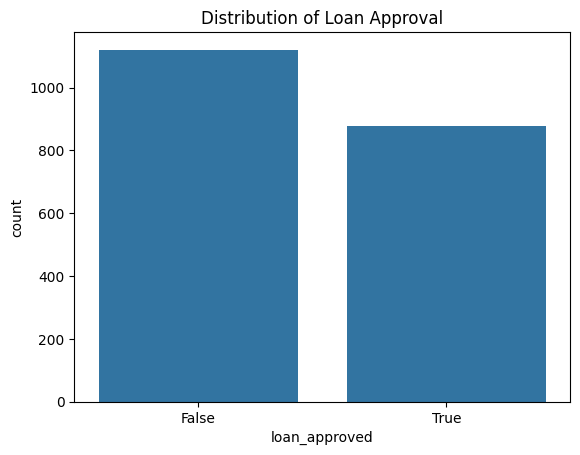

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="loan_approved")
plt.title("Distribution of Loan Approval")
plt.show()

**b) Analyze the relationship between one numerical feature and the target variable.**

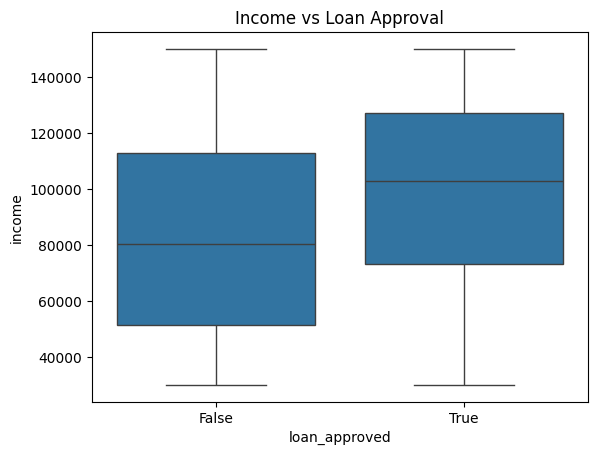

In [26]:
sns.boxplot(
    data=df,
    x="loan_approved",
    y="income"
)
plt.title("Income vs Loan Approval")
plt.show()

**c) Analyze the relationship between Years of Employment and the target variable.**

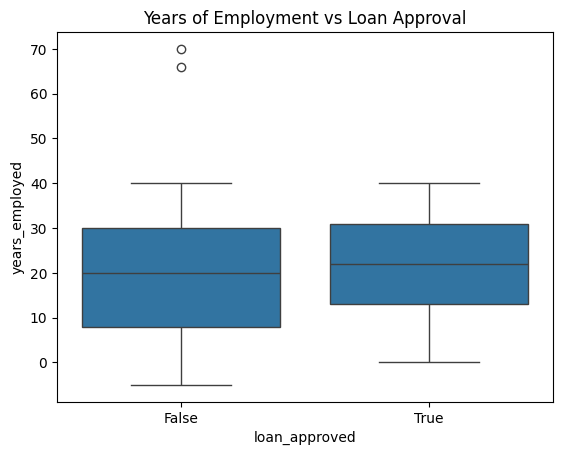

In [27]:
sns.boxplot(
    data=df,
    x="loan_approved",
    y="years_employed"
)
plt.title("Years of Employment vs Loan Approval")
plt.show()

##Q4. Outlier Detection and Treatment

**a) Detect outliers in numerical columns using the IQR method.**

In [28]:
numeric_cols = df.select_dtypes(
    include="number"
).columns.drop("loan_approved", errors="ignore")

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

income Outliers: 0
credit_score Outliers: 3
loan_amount Outliers: 0
years_employed Outliers: 2
points Outliers: 0


**b) Treat outliers using capping techniques**

In [29]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

print("Outliers capped successfully")

Outliers capped successfully


## Q5. Convert target variables into numerical format suitable for model building and drop unnecessary columns.

In [30]:
df["loan_approved"] = (
    df["loan_approved"]
    .astype(str)
    .str.strip()
    .str.upper()
    .map({
        "TRUE": 1,
        "FALSE": 0,
        "1": 1,
        "0": 0
    })
)

df = df.dropna(subset=["loan_approved"])

df["loan_approved"] = df["loan_approved"].astype(int)

df = df.drop(
    columns=["name", "city"],
    errors="ignore"
)

df.head()

,income,credit_score,loan_amount,years_employed,points,loan_approved
0,113810,389.0,39698,27.0,50,0
1,44592,729.0,15446,28.0,55,0
2,33278,584.0,11189,13.0,45,0
3,127196,344.0,48823,29.0,50,0
4,66048,496.0,47174,4.0,25,0


## Q6. Feature Selection and Data Splitting

**a) Separate independent variables (X) and dependent variable (y).**

In [32]:
X = df.drop("loan_approved", axis=1)
y = df["loan_approved"]

X = pd.get_dummies(X, drop_first=True, dtype=int)

**b) Split the dataset into training and testing sets**

In [33]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(1600, 5)
(400, 5)


## Q7. Apply feature scaling to the dataset using StandardScaler.

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed")

Feature scaling completed


## Q8. Logistic Regression Model Building

**a) Train a Logistic Regression model.**

In [35]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)

model.fit(X_train_scaled, y_train)

print("Model trained successfully")

Model trained successfully


**b) Predict the output for test data.**

In [36]:
y_pred = model.predict(X_test_scaled)

print("Predicted values:")
print(y_pred)

Predicted values:
[1 0 1 1 0 1 0 1 0 0 1 0 1 0 1 1 0 1 0 0 1 0 0 0 0 0 1 1 1 1 0 1 0 1 0 1 0
 0 1 1 1 1 0 1 1 1 1 1 0 0 0 0 1 1 0 0 0 1 1 0 0 1 0 1 0 0 0 1 0 1 1 0 1 1
 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 1 0 1 0 0 1 1 0 0 1 0 1 0 0 0 0 1 0 1 0 1 1
 0 0 0 0 0 1 0 0 0 0 1 0 0 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 1 1 0 0 0
 0 0 1 1 1 0 0 0 0 1 0 0 1 0 0 1 0 0 1 1 0 1 1 0 0 0 0 1 1 1 1 0 0 0 1 1 1
 1 1 0 0 1 1 1 1 0 1 1 0 0 0 0 0 1 1 0 0 1 0 1 0 1 0 0 0 1 1 1 0 1 1 1 0 0
 0 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 1 0 1 0 0 0 0 1 1 0 0 1 1 1 1 1 0 1 1 0 1
 0 0 1 0 0 1 0 0 1 1 0 0 1 0 0 1 0 1 0 0 0 1 1 1 1 1 1 1 1 0 1 0 1 1 1 1 0
 1 1 0 0 1 0 1 0 0 1 1 0 1 1 1 1 0 1 0 0 1 1 1 1 0 0 0 0 0 1 1 0 0 0 0 1 0
 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 1 1 1 0 1 0 1 0 0 1
 0 1 1 0 0 0 1 0 0 1 1 1 1 0 0 1 0 0 1 0 0 0 1 0 1 0 0 1 0 0]


## Q9. Model Evaluation – Confusion Matrix

**a) Generate the confusion matrix.**

[[224   0]
 [  0 176]]


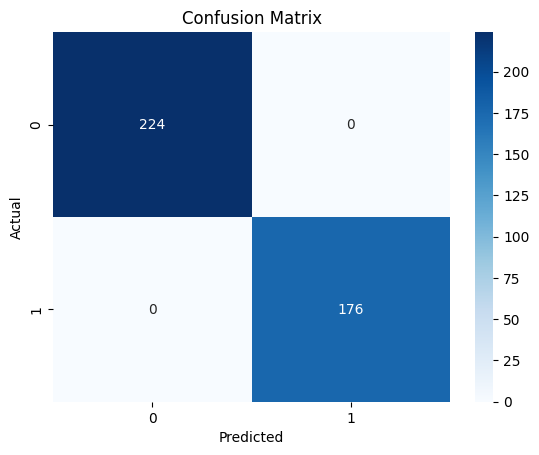

In [37]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

**b) Interpret the results.**

** 1) TN: Correctly predicted loan not approved.**

** 2) FP: Predicted approved, but actually not approved.**

** 3) FN: Predicted not approved, but actually approved.**

** 4) TP: Correctly predicted loan approved.**

##Q10. Model Evaluation – ROC Curve & AUC

**a) Plot the ROC curve**

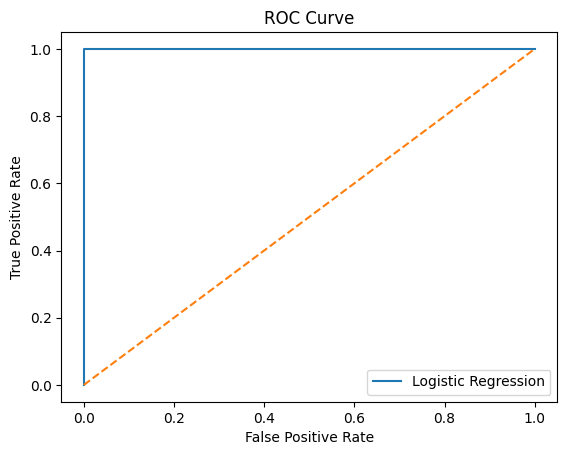

In [39]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob = model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

**b) Calculate the AUC score.**

In [41]:
auc = roc_auc_score(y_test, y_prob)

print("AUC Score:", auc)

AUC Score: 1.0
